# Week 3 Activity: Building and Evaluating Decision Trees

### 🎯 Objective
* Build a decision tree model in Python/R to predict employee performance.
* Evaluate the model's performance and accuracy.
* Understand the construction and interpretation of decision trees.

### 🛠️ Instructions
**1. Dataset Preparation**
* Load the provided dataset: `employee_performance.csv`.
* Display the dataset's structure and the first few rows.

**2. Data Splitting**
* Split the dataset into **training (70%)** and **testing (30%)** subsets using the `scikit-learn` in python / `caTools` package in R.

**3. Build the Decision Tree**
* Use the Python's `scikit-learn` / R's `rpart` package to model and predict the `Performance` variable based on the other features.
* Visualize the generated decision tree using the Python's `sklearn.tree.plot_tree()` / R's `rpart.plot` package.

**4. Model Evaluation**
* Use the trained model to predict performance on the testing dataset.
* Generate a confusion matrix and calculate the model's accuracy.

**5. Reflection (200–300 words)**
* **Patterns:** What key splits or patterns did the tree identify?
* **Performance:** How accurate was the model, and how could it be improved?
* **Application:** How can decision trees be utilized in real-world scenarios?

### 📊 Dataset Description 
* **Employee_ID:** Unique numeric identifier.
* **Department:** Categorical feature (e.g., "Sales," "IT").
* **Years_Experience:** Numeric count of experience years.
* **Age:** Numeric age of the employee.
* **Performance (Target):** Categorical rating ("Low," "Medium," "High").

### 📝 Deliverables & Submission
Combine the following into **1 PDF file**:
* A well-commented Python / R script containing your code.
* A screenshot or exported image of the plotted decision tree.
* The 200–300 word written reflection.

## Workflow
`inspect data → explore data → define X and y → split → fit → predict → evaluate → interpret`

In [80]:
# imports
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# sklearn 
# For splitting the dataset
from sklearn.model_selection import train_test_split

# Decision tree classification and plotting
from sklearn.tree import DecisionTreeClassifier, plot_tree

# for predicting on the test set
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

### 1. Load and inspect the dataset
the dataset contains **250 employee entries** with 10 variables including one identifier (`EmployeeID`), four numerical measurements `[Age, YearsExperience, TrainingHours, JobSatisfaction]`, and five categorical variables `[Department, EducationLevel, Overtime, RemoteWork, Performance]`  
The target is the `Performance` variable

In [81]:
employees = pd.read_csv('../datasets/employee_performance.csv')
employees.info()
display(employees.describe())
employees.head()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   EmployeeID       250 non-null    int64
 1   Age              250 non-null    int64
 2   Department       250 non-null    str  
 3   YearsExperience  250 non-null    int64
 4   EducationLevel   250 non-null    str  
 5   TrainingHours    250 non-null    int64
 6   JobSatisfaction  250 non-null    int64
 7   Overtime         250 non-null    str  
 8   RemoteWork       250 non-null    str  
 9   Performance      250 non-null    str  
dtypes: int64(5), str(5)
memory usage: 19.7 KB


,EmployeeID,Age,YearsExperience,TrainingHours,JobSatisfaction
count,250.000000,250.00000,250.000000,250.000000,250.000000
mean,1125.500000,40.50800,10.020000,30.392000,5.536000
std,72.312977,11.28109,5.652913,11.528485,2.968493
min,1001.000000,22.00000,1.000000,10.000000,1.000000
25%,1063.250000,30.00000,5.000000,20.000000,3.000000
50%,1125.500000,41.00000,10.000000,31.000000,5.500000
75%,1187.750000,50.00000,15.000000,40.000000,8.000000
max,1250.000000,59.00000,19.000000,49.000000,10.000000


,EmployeeID,Age,Department,YearsExperience,EducationLevel,TrainingHours,JobSatisfaction,Overtime,RemoteWork,Performance
0,1001,50,IT,10,Bachelor's,10,10,No,No,Medium
1,1002,36,IT,5,Bachelor's,46,9,Yes,No,Low
2,1003,29,Sales,4,Master's,30,10,Yes,No,Low
3,1004,42,Marketing,2,Master's,35,10,No,No,High
4,1005,40,Sales,10,Bachelor's,45,7,No,Yes,High


In [82]:
employees['Performance'].value_counts()

Performance
Low       123
Medium     88
High       39
Name: count, dtype: int64

### Define the prediction problem
we want to predict the employees performance from the other measurements.  
- **`x` (features/predictors)**: the information given to the model
- **`y` (target/label)**: the answer the model is learning to predict

supervised learning depends on historical data for the algorithm to learn mapping
$$
 f: X \longrightarrow y
$$

for a new employer that is not in the training set, we provide their records and ask the fitted model to predict their performance.

in our case to define x, I removed EmployeeId, and Performance.  
y is the Performance column

In [83]:
x = employees.drop(columns=["EmployeeID", "Performance"])
y = employees["Performance"]

print(f"x shape (observations, features): {x.shape}")
print(f"y shape (observations, ): {y.shape}")

x shape (observations, features): (250, 8)
y shape (observations, ): (250,)


### 2. Split into training and test sets:

- **Training set**: used by the `.fit()` to learn the patterns. 
- **Test set**: held aside until evaluation, used to estimate performance on new/unseen observations.

We're using 70/30 split with the 250 observations.

$$
N_{train}=250\times0.70=175
$$

$$
N_{test}=250\times0.30=75
$$

In [84]:
# encode categorical columns into numerical values 
categorical_cols = x.select_dtypes(include=["object", "category"]).columns
x_encoded = pd.get_dummies(data=x, columns=categorical_cols, dtype=int)

x_train, x_test, y_train, y_test = train_test_split(
    x_encoded,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print(f"Training observations: {len(x_train)}")
print(f"Testing observations: {len(x_test)}")


print(f"\nPerformance count in training set:")
train_summary = y_train.value_counts().to_frame("count")
train_summary["percentage"] = (
    (train_summary["count"]/train_summary["count"].sum())
    .map(lambda p: f"{p: .2%}")
)
print(train_summary)

print(f"\nPerformance count in test set:")
test_summary = y_test.value_counts().to_frame("count")
test_summary["percentage"] = (
    (test_summary["count"]/test_summary["count"].sum())
    .map(lambda p: f"{p: .2%}")
)
print(test_summary)

Training observations: 175
Testing observations: 75

Performance count in training set:
             count percentage
Performance                  
Low             86     49.14%
Medium          62     35.43%
High            27     15.43%

Performance count in test set:
             count percentage
Performance                  
Low             37     49.33%
Medium          26     34.67%
High            12     16.00%


/tmp/ipykernel_25038/2530776918.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = x.select_dtypes(include=["object", "category"]).columns


### 3. Decision Tree
#### 3.1 creat the tree
`DecisionTreeClassifier(...)` creates/configures a model object; it does **not** learn from the data yet.

- `criterion="gini"`: use Gini impurity to evaluate splits, this is the default.
- `max_depth=4`: limit the tree's depth to reduce complexity and help control overfitting. A deeper tree can create very specific rules that fit the training set but generalize poorly.
- `random_state=1234`: make randomized choices reproducible.

Then `.fit(x_train, y_train)` performs the learning: the algorithm searches for feature/threshold splits using the training measurements and their known species labels.  

----
$$
G=1-\sum_{k=1}^{K}p_k^2
$$

Gini is impurity quantifier, the tree keeps branching in a direction that minimized impurity.  
$p_k$ is the proportion of observations of class k within the node k

In [85]:
# create and configure the model
dt_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42,
    max_depth=4
)

# learn the tree structure from the training data
dt_model.fit(X=x_train, y=y_train)

print(f"Tree depth: {dt_model.get_depth()}")
print(f"Number of leaves: {dt_model.get_n_leaves()}")

Tree depth: 4
Number of leaves: 5


#### 3.2 Visualize the decision tree

`plot_tree()` draws the learned tree. It is a visualization of the model **after fitting**.

- `feature_names=X.columns`: show meaningful feature names instead of `x[0]`, `x[1]`, etc.
- `class_names=dt_model.classes_`: show the Performance labels in the model's class order.
- `filled=True`: color nodes by their predicted class, with color intensity reflecting class purity.

Typical node fields:

- `JobSatisfaction <= 3.5`: the split rule at that node;
- `gini`: impurity among training observations reaching the node;
- `samples`: number of training observations reaching the node;
- `value`: class counts at that node, in `dt_model.classes_` order;
- `class`: the node's predicted class (the most represented class).

The displayed `samples` and `value` describe the **training data that reached the node**, not the test data.

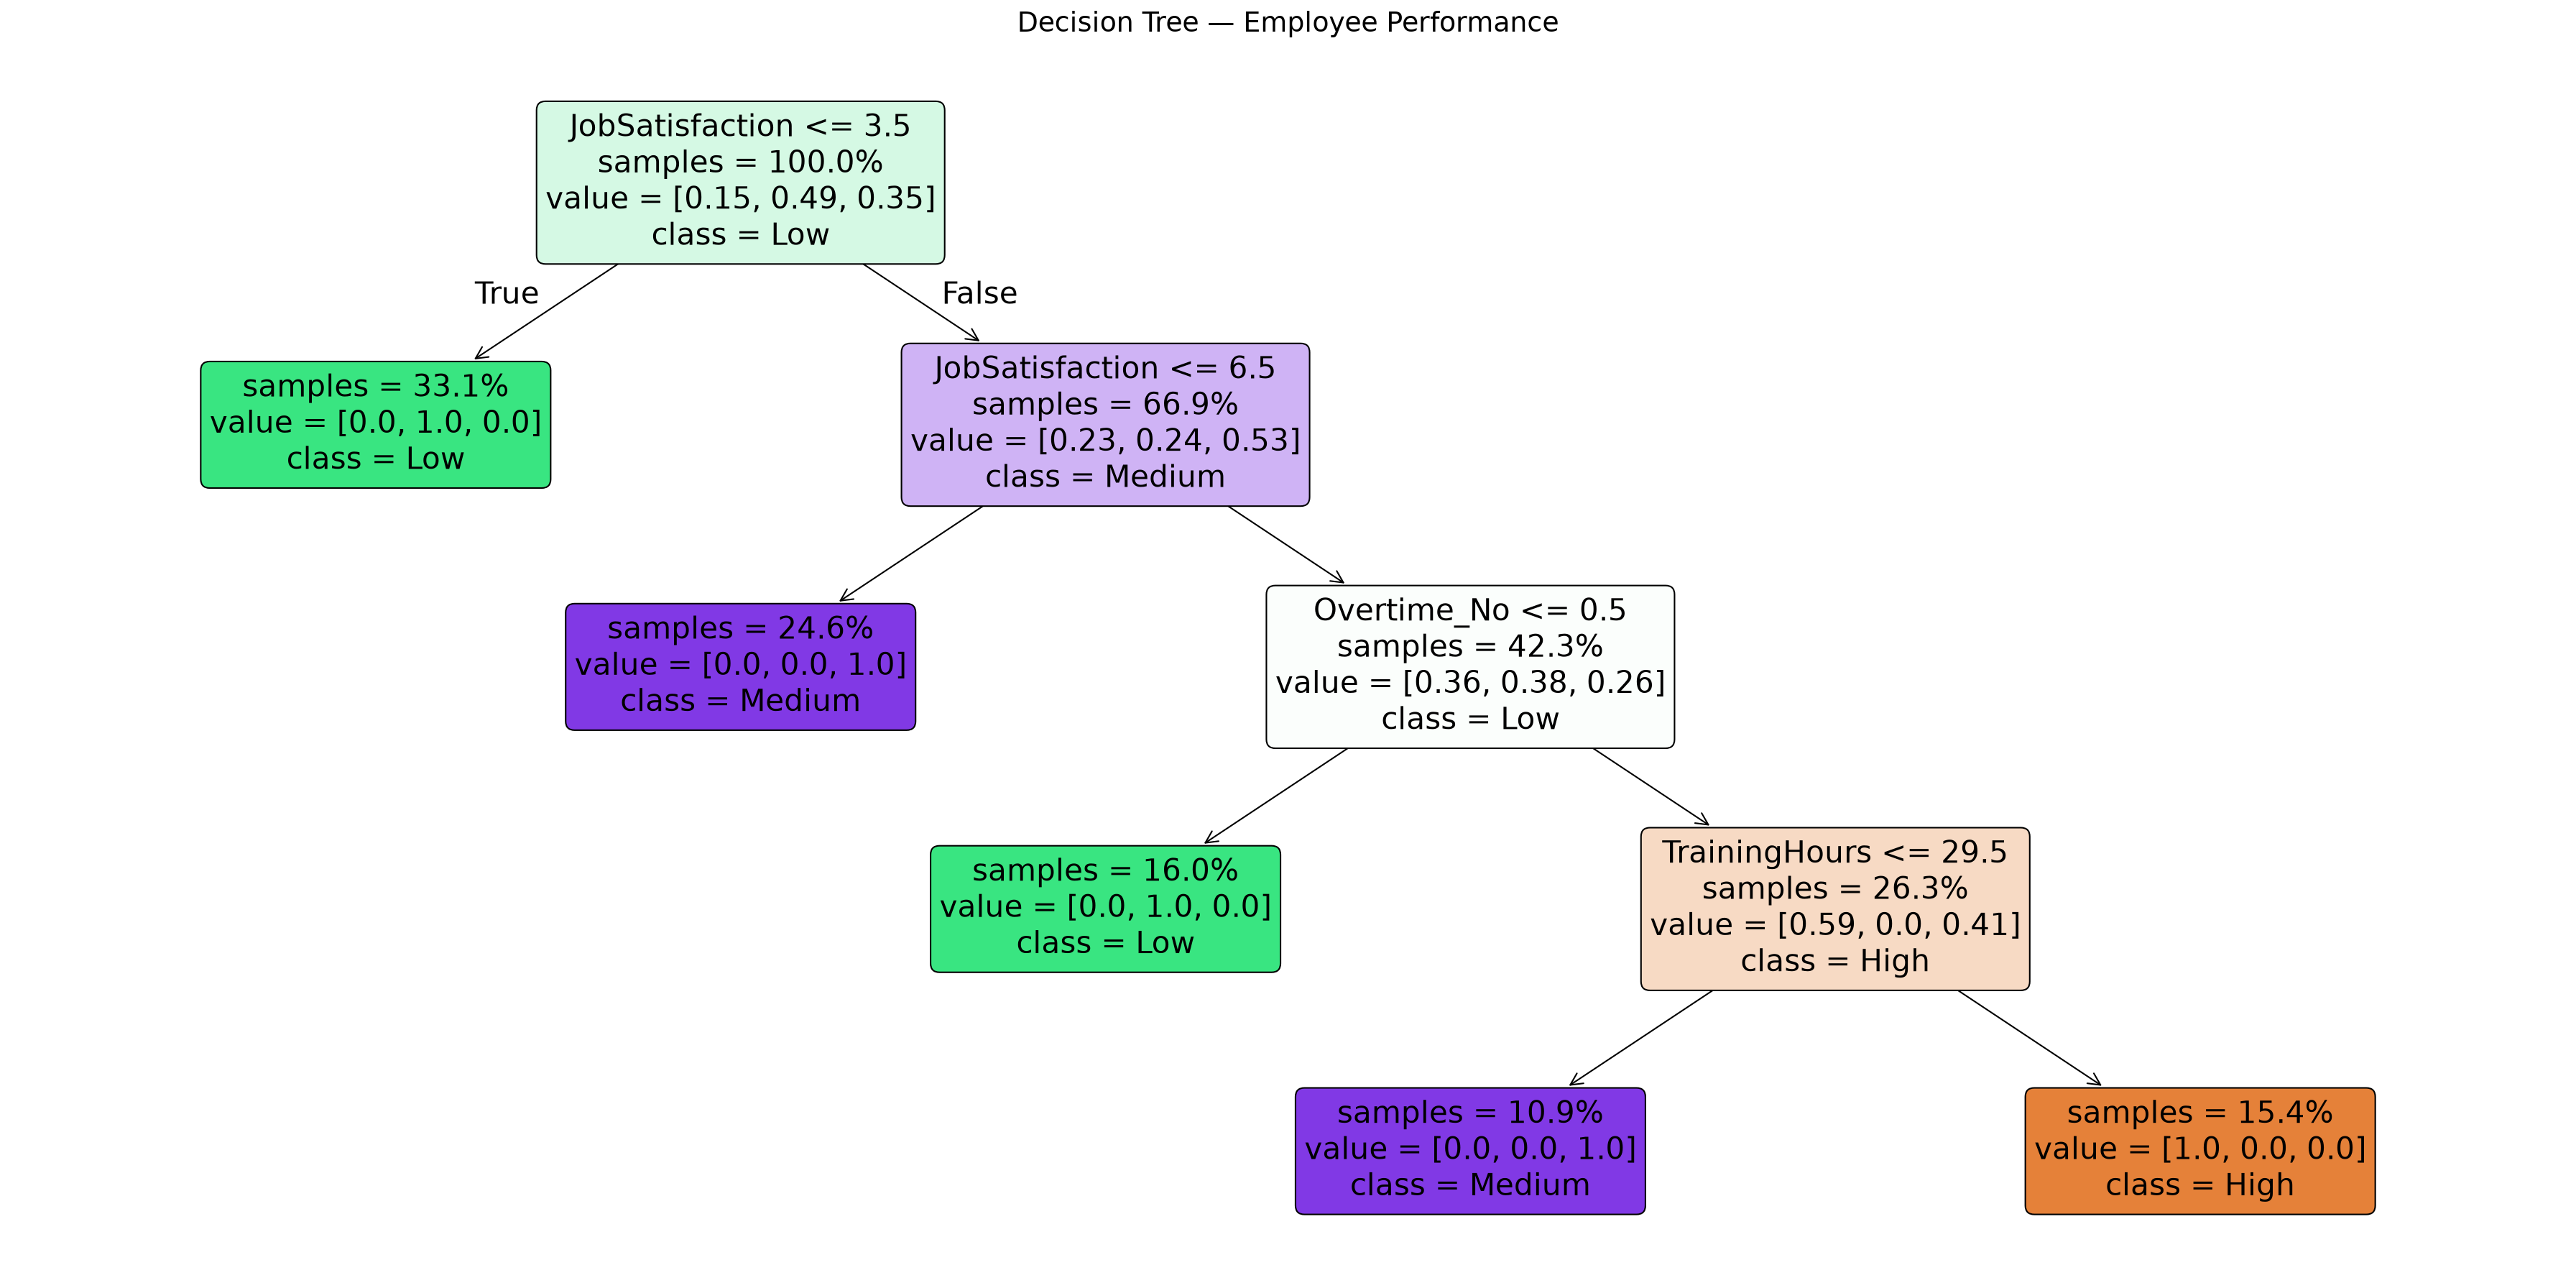

In [95]:
fig, ax = plt.subplots(figsize=(24, 12), dpi=150)

plot_tree(
    dt_model,
    feature_names=x_encoded.columns,
    class_names=dt_model.classes_,
    filled=True,
    rounded=True,
    impurity=False,
    proportion=True,
    precision=2,
    fontsize=20,
    ax=ax
)

ax.set_title(
    "Decision Tree — Employee Performance",
    fontsize=18,
    pad=20
)

plt.tight_layout()
plt.show()

#### After fitting, predict on the held-out test set:
After fitting, `.predict(x_test)` sends each test employee through the learned tree and returns a predicted performance.  

then we define the accurace score by comparing the predicted, with the actual y_test performance values.

In [87]:
dt_predictions = dt_model.predict(X=x_test)

print(f"first 10 predictions:   {dt_predictions[:10].tolist()}")
print(f"first 10 actual values: {y_test.iloc[:10].tolist()}")

first 10 predictions:   ['Medium', 'Low', 'High', 'Low', 'High', 'Low', 'Medium', 'Low', 'Medium', 'Medium']
first 10 actual values: ['Medium', 'Low', 'High', 'Low', 'High', 'Low', 'Medium', 'Low', 'Medium', 'Medium']


#### Evaluate accuracy and confusion matrix
**Accuracy** is the fraction of test observations classified correctly:

$$
\text{Accuracy}=\frac{\text{number of correct predictions}}{\text{number of test observations}}
$$

For a multiclass confusion matrix, the diagonal contains correct predictions. Off-diagonal cells show which actual classes were mistaken for which predicted classes.

In scikit-learn, `confusion_matrix(y_test, predictions)` uses **rows = actual classes** and **columns = predicted classes**. We set the label order explicitly so the table is easy to read.

In [88]:
dt_accuracy = accuracy_score(y_true=y_test, y_pred=dt_predictions)
print(f"Decision Tree accuracy: {dt_accuracy: 0.3f}   ({dt_accuracy: .2%})")

labels = dt_model.classes_
dt_cm = confusion_matrix(y_true=y_test, y_pred=dt_predictions)
display(
    pd.DataFrame(
        data=dt_cm,
        index=pd.Index(data=labels, name="Actual"),
        columns=pd.Index(data=labels, name="Predicted")
    )
)

print("\nClassification Report:")
print(classification_report(y_true=y_test, y_pred=dt_predictions))

Decision Tree accuracy:  1.000   ( 100.00%)


Predicted,High,Low,Medium
Actual,,,
High,12,0,0
Low,0,37,0
Medium,0,0,26



Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        12
         Low       1.00      1.00      1.00        37
      Medium       1.00      1.00      1.00        26

    accuracy                           1.00        75
   macro avg       1.00      1.00      1.00        75
weighted avg       1.00      1.00      1.00        75

